Shape: (12540, 7)
Date range: 2021-01-04 -> 2025-12-30
Companies: ['AAPL', 'AMZN', 'JNJ', 'JPM', 'KO', 'LLY', 'MSFT', 'NVDA', 'TSLA', 'XOM']

--- Data quality checks ---


,result
Missing values (total),0
Duplicate rows,0
"Duplicate (ticker, date) pairs",0
Close <= 0,0
Volume == 0,0
High < Low,0
Tickers with unsorted dates,0
Same rows per ticker?,True


Extreme moves (|return| > 20%): 3

--- Daily returns (first 5 rows) ---


ticker,AAPL,JPM,MSFT,TSLA,XOM
date,,,,,
2021-01-05,0.012363,0.005441,0.000965,0.007317,0.048193
2021-01-06,-0.033661,0.046956,-0.025929,0.028390,0.025517
2021-01-07,0.034124,0.032839,0.028457,0.079447,0.007846
2021-01-08,0.008631,0.001104,0.006093,0.078403,0.011121
2021-01-11,-0.023249,0.014924,-0.009698,-0.078214,0.030356



--- Volatility ---


,daily_volatility,annualized_volatility
ticker,,
TSLA,3.83%,60.76%
AAPL,1.76%,27.87%
XOM,1.70%,27.03%
MSFT,1.62%,25.72%
JPM,1.53%,24.28%


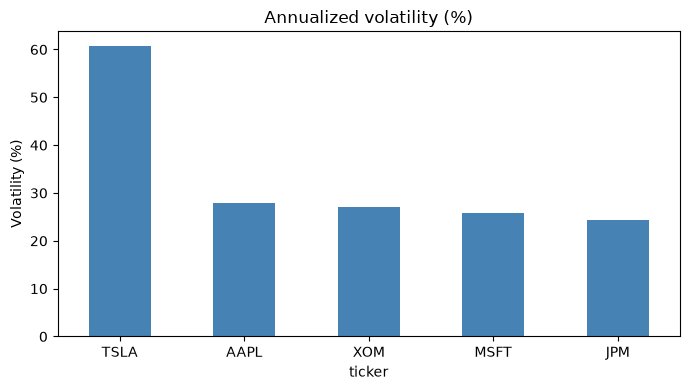

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

FILE = "../../data/raw/yahoo_prices_raw.csv"

df = pd.read_csv(FILE, parse_dates=["date"])

print("Shape:", df.shape)
print(
    "Date range:",
    df["date"].min().date(),
    "->",
    df["date"].max().date()
)
print("Companies:", sorted(df["ticker"].unique()))

# Data quality checks
checks = {}

checks["Missing values (total)"] = int(df.isna().sum().sum())
checks["Duplicate rows"] = int(df.duplicated().sum())
checks["Duplicate (ticker, date) pairs"] = int(
    df.duplicated(["ticker", "date"]).sum()
)
checks["Close <= 0"] = int((df["close"] <= 0).sum())
checks["Volume == 0"] = int((df["volume"] == 0).sum())
checks["High < Low"] = int((df["high"] < df["low"]).sum())

checks["Tickers with unsorted dates"] = int(
    (
        ~df.groupby("ticker")["date"].apply(
            lambda s: s.is_monotonic_increasing
        )
    ).sum()
)

checks["Same rows per ticker?"] = bool(
    df.groupby("ticker").size().nunique() == 1
)

print("\n--- Data quality checks ---")
display(pd.Series(checks, name="result").to_frame())

# Sort data and calculate daily returns
df = df.sort_values(
    ["ticker", "date"]
).reset_index(drop=True)

df["daily_return"] = df.groupby("ticker")["close"].pct_change()

print(
    "Extreme moves (|return| > 20%):",
    int((df["daily_return"].abs() > 0.20).sum())
)

# Select companies
companies = ["AAPL", "MSFT", "TSLA", "JPM", "XOM"]
sub = df[df["ticker"].isin(companies)]

returns = sub.pivot(
    index="date",
    columns="ticker",
    values="daily_return"
).dropna()

print("\n--- Daily returns (first 5 rows) ---")
display(returns.head())

# Volatility analysis
vol = pd.DataFrame({
    "daily_volatility": returns.std(),
    "annualized_volatility": returns.std() * np.sqrt(252),
}).sort_values("annualized_volatility", ascending=False)

print("\n--- Volatility ---")
display(vol.style.format("{:.2%}"))

# Plot annualized volatility
(
    vol["annualized_volatility"] * 100
).plot(
    kind="bar",
    figsize=(7, 4),
    color="steelblue"
)

plt.title("Annualized volatility (%)")
plt.ylabel("Volatility (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [1]:
import sys
print("Python:", sys.executable)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("All imports successful!")

Python: c:\Users\Laila Elsisi\AppData\Local\Python\pythoncore-3.14-64\python.exe


Matplotlib is building the font cache; this may take a moment.


Pandas: 3.0.6
NumPy: 2.5.4
All imports successful!
